# LIBRAIRIE

In [273]:
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier




In [274]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler


- pour importer les algorithmsf(+ les fonctions ou code du notebook.ipynb/partie I du projet) qu'on va par la suite les utiliser.

In [275]:
import sys
import io
from contextlib import redirect_stdout, redirect_stderr

# Supprimer l'affichage pendant l'import
f = io.StringIO()
with redirect_stdout(f), redirect_stderr(f):
    import import_ipynb
    import notebook

# Maintenant vous avez accès aux variables sans l'affichage
print("Import réussi !")

Import réussi !


# CHARGEMENT DES DONNEES

In [276]:
df2 = pd.read_csv('credit.data', header=None, sep='\s+', na_values='?')
# Afficher les premières lignes pour inspection
print("Premières lignes du dataset")
print(df2.head())
print("\n")
print(f"Type deu dataset : {type(df2)}") # on voit bien quil est en dataframe

Premières lignes du dataset
  0      1      2  3  4  5  6     7  8  9   10 11 12     13   14 15
0  b  30.83  0.000  u  g  w  v  1.25  t  t   1  f  g  202.0    0  +
1  a  58.67  4.460  u  g  q  h  3.04  t  t   6  f  g   43.0  560  +
2  a  24.50  0.500  u  g  q  h  1.50  t  f   0  f  g  280.0  824  +
3  b  27.83  1.540  u  g  w  v  3.75  t  t   5  t  g  100.0    3  +
4  b  20.17  5.625  u  g  w  v  1.71  t  f   0  f  s  120.0    0  +


Type deu dataset : <class 'pandas.core.frame.DataFrame'>


# TRANSFORMATION EN NUMPY

In [277]:
# 2. Transformation en numpy array
df2_numpy = df2.values
print(f" Transformation en numpu array\n {df2_numpy}")
print(f"Type de data_array : {type(df2_numpy)}") # transformation reussi en numpy array

 Transformation en numpu array
 [['b' 30.83 0.0 ... 202.0 0 '+']
 ['a' 58.67 4.46 ... 43.0 560 '+']
 ['a' 24.5 0.5 ... 280.0 824 '+']
 ...
 ['a' 25.25 13.5 ... 200.0 1 '-']
 ['b' 17.92 0.205 ... 280.0 750 '-']
 ['b' 35.0 3.375 ... 0.0 0 '-']]
Type de data_array : <class 'numpy.ndarray'>


## SEPARATION DES X ET Y

In [278]:
# Séparation des caractéristiques (X) et de la variable cible (y)
X = df2_numpy[:, :-1]  # Toutes les colonnes sauf la dernière
y = df2_numpy[:, -1]   # Dernière colonne (status)

## DETAIL DU DATASET

In [279]:
print(f"Shape de X (caractéristiques): {X.shape}")
print(f"Shape de y (target): {y.shape}")
print("\nPremières lignes de X:")
print(X[:3])
print("\nPremières valeurs de y:")
print(y[:3])

Shape de X (caractéristiques): (688, 15)
Shape de y (target): (688,)

Premières lignes de X:
[['b' 30.83 0.0 'u' 'g' 'w' 'v' 1.25 't' 't' 1 'f' 'g' 202.0 0]
 ['a' 58.67 4.46 'u' 'g' 'q' 'h' 3.04 't' 't' 6 'f' 'g' 43.0 560]
 ['a' 24.5 0.5 'u' 'g' 'q' 'h' 1.5 't' 'f' 0 'f' 'g' 280.0 824]]

Premières valeurs de y:
['+' '+' '+']


## SUPPRIMER LES NAN

In [280]:
# Colonnes avec des valeurs numériques : 1, 2, 7, 10, 13, 14
numerical_indices = [1, 2, 7, 10, 13, 14]

# Création du sous-ensemble avec seulement les variables numériques
X_numerical = X[:, numerical_indices]

In [281]:
# Remplacer '?' par nan et convertir en float
X_numerical = np.where(X_numerical == '?', np.nan, X_numerical)
X_numerical = X_numerical.astype(float)

In [282]:
print(f"Shape du sous-ensemble numérique: {X_numerical.shape}")
print(f"Type: {X_numerical.dtype}")
print("\nPremières lignes:")
print(X_numerical[:5])

Shape du sous-ensemble numérique: (688, 6)
Type: float64

Premières lignes:
[[ 30.83    0.      1.25    1.    202.      0.   ]
 [ 58.67    4.46    3.04    6.     43.    560.   ]
 [ 24.5     0.5     1.5     0.    280.    824.   ]
 [ 27.83    1.54    3.75    5.    100.      3.   ]
 [ 20.17    5.625   1.71    0.    120.      0.   ]]


In [283]:
# Supprimer les individus avec des valeurs manquantes (nan)
mask = ~np.any(np.isnan(X_numerical), axis=1)
X_clean = X_numerical[mask]
y_clean = y[mask]

In [284]:
print(f"Shape après suppression des NaN - X_clean: {X_clean.shape}")
print(f"Shape après suppression des NaN - y_clean: {y_clean.shape}")

Shape après suppression des NaN - X_clean: (666, 6)
Shape après suppression des NaN - y_clean: (666,)


In [285]:
# Analyser les propriétés
print(f"\nTaille de l'échantillon: {X_clean.shape[0]} instances")
print(f"Nombre de caractéristiques numériques: {X_clean.shape[1]}")


Taille de l'échantillon: 666 instances
Nombre de caractéristiques numériques: 6


## CLASSE NEGATIVE/POSITIVE

In [286]:
# Compter les exemples positifs et négatifs
unique, counts = np.unique(y_clean, return_counts=True)
print(f"\nDistribution des classes: {dict(zip(unique, counts))}")


Distribution des classes: {'+': 299, '-': 367}


In [287]:
# Binariser la target (+ en 1 et - en 0)
y_binary = np.where(y_clean == '+', 1, 0)

In [288]:
print(f"\nAprès binarisation {dict(zip(['0 (-)', '1 (+)'], np.bincount(y_binary)))}")


Après binarisation {'0 (-)': 367, '1 (+)': 299}


In [289]:
print(X_clean[:3])
print(y_clean[:3])
print(y_binary[:3])

[[ 30.83   0.     1.25   1.   202.     0.  ]
 [ 58.67   4.46   3.04   6.    43.   560.  ]
 [ 24.5    0.5    1.5    0.   280.   824.  ]]
['+' '+' '+']
[1 1 1]


In [290]:
print("Target binarisée:")
print("Classe 0 (-):", np.sum(y_binary == 0))
print("Classe 1 (+):", np.sum(y_binary == 1))

Target binarisée:
Classe 0 (-): 367
Classe 1 (+): 299


# COMPARAISON DES ALGOS

### DIVISION TRAIN TEST 

In [291]:
# Division train-test pour utiliser best_model, best_model_name, all_results = notebook.run_classifiers_train_test

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_binary, test_size=0.3, random_state=42, stratify=y_binary
)

In [292]:
print(f"\nDivision train-test:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


Division train-test:
X_train: (466, 6), y_train: (466,)
X_test: (200, 6), y_test: (200,)


### LES ALGOS

In [293]:
print("Algorithmes:", list(notebook.algorithms.keys()))

Algorithmes: ['CART', 'KNN-5', 'MLP']


Début de l'apprentissage...
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6750
Precision:   0.6316
Recall:      0.6667
Score final: 0.6708 (Accuracy + Recall)/2
AUC:         0.6742

 KNN-5
------------------------------
Accuracy:    0.6850
Precision:   0.6901
Recall:      0.5444
Score final: 0.6147 (Accuracy + Recall)/2
AUC:         0.7284

 MLP
------------------------------
Accuracy:    0.7200
Precision:   0.7179
Recall:      0.6222
Score final: 0.6711 (Accuracy + Recall)/2
AUC:         0.7460

COMPARAISON DES MODÈLES
CART       : 0.6708
KNN-5      : 0.6147
MLP        : 0.6711

 MEILLEUR MODÈLE: MLP avec un score de 0.6711

VISUALISATIONS

Courbes ROC :


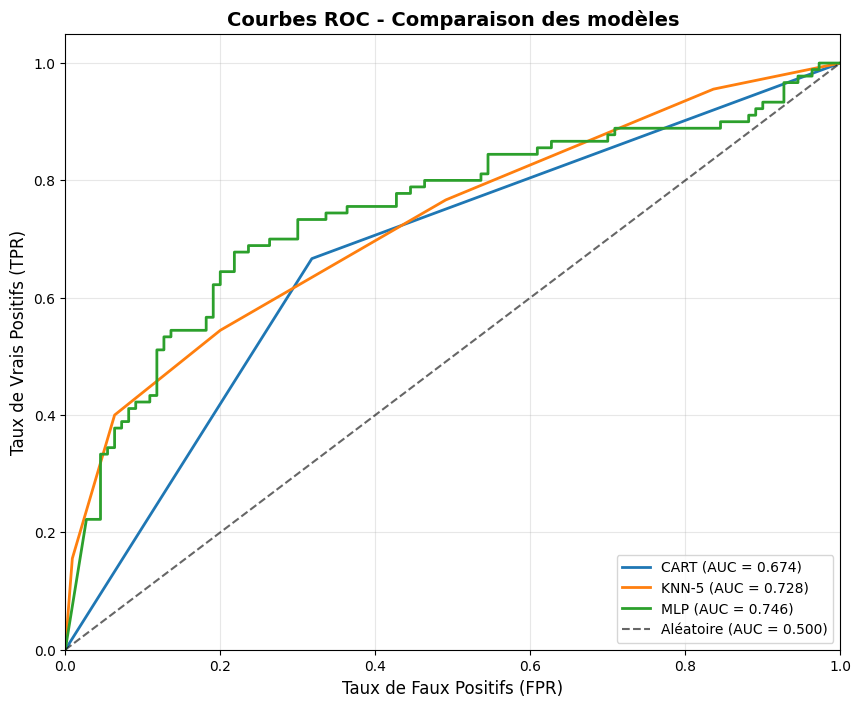


Matrices de confusion :


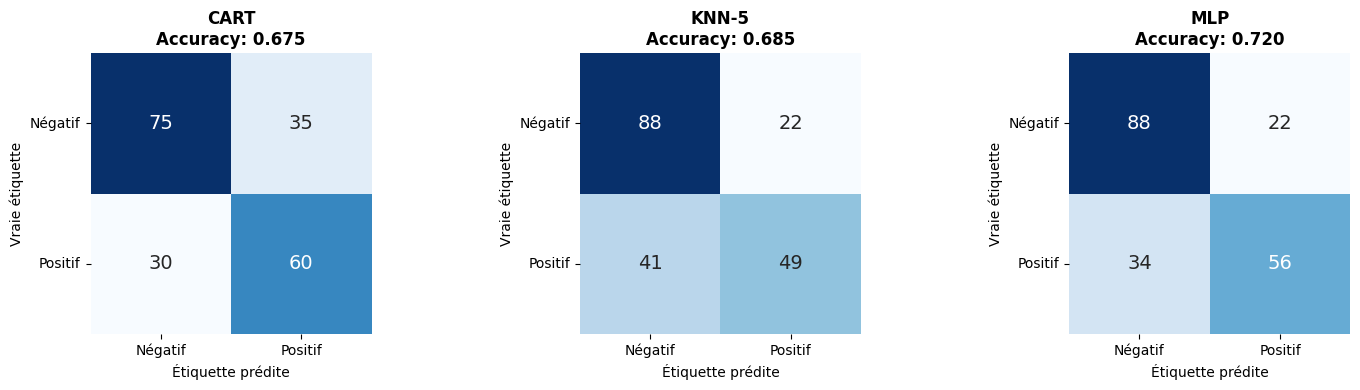


 MEILLEUR MODÈLE SÉLECTIONNÉ: MLP


In [294]:
print("Début de l'apprentissage...")
best_model, best_model_name, all_results = notebook.run_classifiers_train_test(
    X_train, X_test, y_train, y_test
)

# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC
print("\nCourbes ROC :")
notebook.plot_roc_curves(all_results)

# Matrices de confusion
print("\nMatrices de confusion :")
notebook.plot_confusion_matrices(all_results)

print(f"\n MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")

# NORMALISATION (StandardScaler/MinMaxScaler)


In [295]:
# Normalisation des données
print("NORMALISATION DES DONNÉES")
X_train_std, X_test_std, scaler_std = notebook.normalize_data(X_train, X_test, method='standard')

print("Données normalisées avec StandardScaler")
print(f"Shape X_train normalisé: {X_train_std.shape}")
print(f"Shape X_test normalisé: {X_test_std.shape}")

# Statistiques avant/après normalisation
print("\nCOMPARAISON AVANT/APRÈS NORMALISATION")
print("Moyennes (avant normalisation):", np.mean(X_train, axis=0)[:5])  # 5 premières features
print("Moyennes (après normalisation):", np.mean(X_train_std, axis=0)[:5])
print("\nÉcart-types (avant normalisation):", np.std(X_train, axis=0)[:5])
print("Écart-types (après normalisation):", np.std(X_train_std, axis=0)[:5])

NORMALISATION DES DONNÉES
Données normalisées avec StandardScaler
Shape X_train normalisé: (466, 6)
Shape X_test normalisé: (200, 6)

COMPARAISON AVANT/APRÈS NORMALISATION
Moyennes (avant normalisation): [ 31.96843348   4.84853004   2.18312232   2.57725322 183.62446352]
Moyennes (après normalisation): [ 0.  0.  0. -0. -0.]

Écart-types (avant normalisation): [ 11.93751385   5.05632146   3.36891565   5.35754229 172.57950386]
Écart-types (après normalisation): [1. 1. 1. 1. 1.]


In [296]:
# Exécution des modèles sur données normalisées
print("=" * 70)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)")
print("=" * 70)

best_model_std, best_model_name_std, results_std = notebook.run_classifiers_train_test(
    X_train_std, X_test_std, y_train, y_test
)

APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6750
Precision:   0.6316
Recall:      0.6667
Score final: 0.6708 (Accuracy + Recall)/2
AUC:         0.6742

 KNN-5
------------------------------
Accuracy:    0.7250
Precision:   0.7465
Recall:      0.5889
Score final: 0.6569 (Accuracy + Recall)/2
AUC:         0.7903

 MLP
------------------------------
Accuracy:    0.8000
Precision:   0.7778
Recall:      0.7778
Score final: 0.7889 (Accuracy + Recall)/2
AUC:         0.8355

COMPARAISON DES MODÈLES
CART       : 0.6708
KNN-5      : 0.6569
MLP        : 0.7889

 MEILLEUR MODÈLE: MLP avec un score de 0.7889


# Traitement de données manquantes

In [297]:
col_num = [1, 2, 7, 10, 13, 14]
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]

print("Colonnes numériques:", col_num)
print("Colonnes catégorielles:", col_cat)

Colonnes numériques: [1, 2, 7, 10, 13, 14]
Colonnes catégorielles: [0, 3, 4, 5, 6, 8, 9, 11, 12]


In [298]:
# Copier les colonnes catégorielles
X_cat = np.copy(X[:, col_cat])

print("Shape des données catégorielles:", X_cat.shape)
print("\nExemple de données catégorielles avant transformation:")
print(X_cat[:5])

# Transformer les valeurs catégorielles en valeurs numériques
# Convertir en str afin d'éviter les comparaisons entre types (ex: float vs str) lors de np.unique
X_cat_encoded = np.empty(X_cat.shape, dtype=int)
for col_id in range(len(col_cat)):
    col_values = X_cat[:, col_id].astype(str)
    unique_val, val_idx = np.unique(col_values, return_inverse=True)
    X_cat_encoded[:, col_id] = val_idx
    print(f"\nColonne {col_cat[col_id]}: {len(unique_val)} modalités uniques")

X_cat = X_cat_encoded

print("\nDonnées catégorielles après transformation:")
print(X_cat[:5])

Shape des données catégorielles: (688, 9)

Exemple de données catégorielles avant transformation:
[['b' 'u' 'g' 'w' 'v' 't' 't' 'f' 'g']
 ['a' 'u' 'g' 'q' 'h' 't' 't' 'f' 'g']
 ['a' 'u' 'g' 'q' 'h' 't' 'f' 'f' 'g']
 ['b' 'u' 'g' 'w' 'v' 't' 't' 't' 'g']
 ['b' 'u' 'g' 'w' 'v' 't' 'f' 'f' 's']]

Colonne 0: 3 modalités uniques

Colonne 3: 4 modalités uniques

Colonne 4: 4 modalités uniques

Colonne 5: 15 modalités uniques

Colonne 6: 10 modalités uniques

Colonne 8: 2 modalités uniques

Colonne 9: 2 modalités uniques

Colonne 11: 2 modalités uniques

Colonne 12: 3 modalités uniques

Données catégorielles après transformation:
[[ 1  2  0 13  8  1  1  0  0]
 [ 0  2  0 11  3  1  1  0  0]
 [ 0  2  0 11  3  1  0  0  0]
 [ 1  2  0 13  8  1  1  1  0]
 [ 1  2  0 13  8  1  0  0  2]]


In [299]:
# Remplacer '0' qui correspond à '?' par la valeur la plus fréquente
# Note: après unique(), '?' devient souvent la valeur 0
X_cat = X_cat.astype(float)

# Imputer avec la stratégie most_frequent
imp_cat = SimpleImputer(missing_values=0, strategy='most_frequent')
X_cat = imp_cat.fit_transform(X_cat)

print("Valeurs manquantes dans X_cat après imputation:", np.sum(np.isnan(X_cat)))
print("\nDonnées catégorielles après imputation:")
print(X_cat[:5])

Valeurs manquantes dans X_cat après imputation: 0

Données catégorielles après imputation:
[[ 1.  2.  3. 13.  8.  1.  1.  1.  2.]
 [ 1.  2.  3. 11.  3.  1.  1.  1.  2.]
 [ 1.  2.  3. 11.  3.  1.  1.  1.  2.]
 [ 1.  2.  3. 13.  8.  1.  1.  1.  2.]
 [ 1.  2.  3. 13.  8.  1.  1.  1.  2.]]


In [300]:
# Copier les colonnes numériques
X_num = np.copy(X[:, col_num])

print("Shape des données numériques:", X_num.shape)
print("\nExemple de données numériques avant transformation:")
print(X_num[:5])

# Remplacer '?' par nan
X_num[X_num == '?'] = np.nan
X_num = X_num.astype(float)

print("\nNombre de valeurs manquantes par colonne numérique:")
for i in range(X_num.shape[1]):
    count_nan = np.sum(np.isnan(X_num[:, i]))
    print(f"Colonne {col_num[i]}: {count_nan} NaN")

Shape des données numériques: (688, 6)

Exemple de données numériques avant transformation:
[[30.83 0.0 1.25 1 202.0 0]
 [58.67 4.46 3.04 6 43.0 560]
 [24.5 0.5 1.5 0 280.0 824]
 [27.83 1.54 3.75 5 100.0 3]
 [20.17 5.625 1.71 0 120.0 0]]

Nombre de valeurs manquantes par colonne numérique:
Colonne 1: 12 NaN
Colonne 2: 0 NaN
Colonne 7: 0 NaN
Colonne 10: 0 NaN
Colonne 13: 11 NaN
Colonne 14: 0 NaN


In [301]:
# Imputer avec la moyenne
imp_num = SimpleImputer(missing_values=np.nan, strategy='mean')
X_num = imp_num.fit_transform(X_num)

print("Valeurs manquantes dans X_num après imputation:", np.sum(np.isnan(X_num)))
print("\nDonnées numériques après imputation:")
print(X_num[:5])
print("\nStatistiques des variables numériques:")
print("Moyennes:", np.mean(X_num, axis=0))
print("Écarts-types:", np.std(X_num, axis=0))

Valeurs manquantes dans X_num après imputation: 0

Données numériques après imputation:
[[ 30.83    0.      1.25    1.    202.      0.   ]
 [ 58.67    4.46    3.04    6.     43.    560.   ]
 [ 24.5     0.5     1.5     0.    280.    824.   ]
 [ 27.83    1.54    3.75    5.    100.      3.   ]
 [ 20.17    5.625   1.71    0.    120.      0.   ]]

Statistiques des variables numériques:
Moyennes: [  31.5189497     4.76856105    2.22659884    2.39825581  184.01477105
 1019.47093023]
Écarts-types: [  11.760483      4.97787639    3.34786991    4.86367616  172.28434385
 5213.71865786]


In [302]:
# Encoder les variables catégorielles en variables binaires
encoder = OneHotEncoder(sparse_output=False)
X_cat_bin = encoder.fit_transform(X_cat)

print("Shape après One-Hot Encoding:", X_cat_bin.shape)
print("Nombre de features catégorielles binaires créées:", X_cat_bin.shape[1])
print("\nExemple de données après One-Hot Encoding:")
print(X_cat_bin[:5, :10])  # Afficher les 10 premières colonnes

Shape après One-Hot Encoding: (688, 36)
Nombre de features catégorielles binaires créées: 36

Exemple de données après One-Hot Encoding:
[[1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [1. 0. 0. 1. 0. 0. 0. 1. 0. 0.]]


In [303]:
# Normaliser les variables continues
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

print("Données numériques après normalisation:")
print("Moyennes:", np.mean(X_num_scaled, axis=0))
print("Écarts-types:", np.std(X_num_scaled, axis=0))
print("\nExemple de données normalisées:")
print(X_num_scaled[:5])

Données numériques après normalisation:
Moyennes: [-0.  0.  0. -0.  0.  0.]
Écarts-types: [1. 1. 1. 1. 1. 1.]

Exemple de données normalisées:
[[-0.05858175 -0.95795088 -0.29170752 -0.2874895   0.10439271 -0.19553624]
 [ 2.30866796 -0.06198648  0.2429608   0.74053947 -0.81850021 -0.0881273 ]
 [-0.59682495 -0.85750644 -0.21703318 -0.49309529  0.55713263 -0.03749165]
 [-0.31367332 -0.648582    0.45503595  0.53493368 -0.4876518  -0.19496083]
 [-0.96500711  0.17204906 -0.15430672 -0.49309529 -0.37156464 -0.19553624]]


In [304]:
# Concaténer les données catégorielles encodées et les données numériques normalisées
X_final = np.concatenate([X_cat_bin, X_num_scaled], axis=1)

print("Shape du jeu de données final:", X_final.shape)
print("Nombre total de features:", X_final.shape[1])
print("  - Features catégorielles (binaires):", X_cat_bin.shape[1])
print("  - Features numériques (normalisées):", X_num_scaled.shape[1])

Shape du jeu de données final: (688, 42)
Nombre total de features: 42
  - Features catégorielles (binaires): 36
  - Features numériques (normalisées): 6


In [305]:
# Vérifier les formes
print("X_final shape:", X_final.shape)
print("y_binary shape:", y_binary.shape)

# Vérifier les types
print("\nType de X_final:", type(X_final))
print("Type de y_binary:", type(y_binary))

# Comme X_final est un array NumPy, on doit simplement tronquer au minimum
min_length = min(X_final.shape[0], y_binary.shape[0])
print(f"\nLongueur minimale: {min_length}")
print(f"Échantillons à supprimer de X_final: {X_final.shape[0] - min_length}")

# Tronquer X_final pour correspondre à y_binary
X_final_trimmed = X_final[:min_length]
y_binary_trimmed = y_binary[:min_length]

print("\nAprès ajustement:")
print("X_final_trimmed shape:", X_final_trimmed.shape)
print("y_binary_trimmed shape:", y_binary_trimmed.shape)

# Vérifier la distribution des classes
print("\nDistribution des classes:")
unique, counts = np.unique(y_binary_trimmed, return_counts=True)
for u, c in zip(unique, counts):
    print(f"Classe {int(u)}: {c}")

# Maintenant faire le split
X_train, X_test, Y_train, Y_test = train_test_split(
    X_final_trimmed, y_binary_trimmed, test_size=0.5, random_state=1
)

print("\nSéparation train/test:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train - Classe 0:", np.sum(Y_train == 0), "| Classe 1:", np.sum(Y_train == 1))
print("Y_test - Classe 0:", np.sum(Y_test == 0), "| Classe 1:", np.sum(Y_test == 1))

X_final shape: (688, 42)
y_binary shape: (666,)

Type de X_final: <class 'numpy.ndarray'>
Type de y_binary: <class 'numpy.ndarray'>

Longueur minimale: 666
Échantillons à supprimer de X_final: 22

Après ajustement:
X_final_trimmed shape: (666, 42)
y_binary_trimmed shape: (666,)

Distribution des classes:
Classe 0: 367
Classe 1: 299

Séparation train/test:
X_train shape: (333, 42)
X_test shape: (333, 42)
Y_train - Classe 0: 179 | Classe 1: 154
Y_test - Classe 0: 188 | Classe 1: 145


=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6126
Precision:   0.5588
Recall:      0.5241
Score final: 0.5684 (Accuracy + Recall)/2
AUC:         0.6025

 KNN-5
------------------------------
Accuracy:    0.7237
Precision:   0.7054
Recall:      0.6276
Score final: 0.6757 (Accuracy + Recall)/2
AUC:         0.7543

 MLP
------------------------------
Accuracy:    0.6517
Precision:   0.6028
Recall:      0.5862
Score final: 0.6189 (Accuracy + Recall)/2
AUC:         0.7258

COMPARAISON DES MODÈLES
CART       : 0.5684
KNN-5      : 0.6757
MLP        : 0.6189

 MEILLEUR MODÈLE: KNN-5 avec un score de 0.6757

VISUALISATIONS

Courbes ROC :


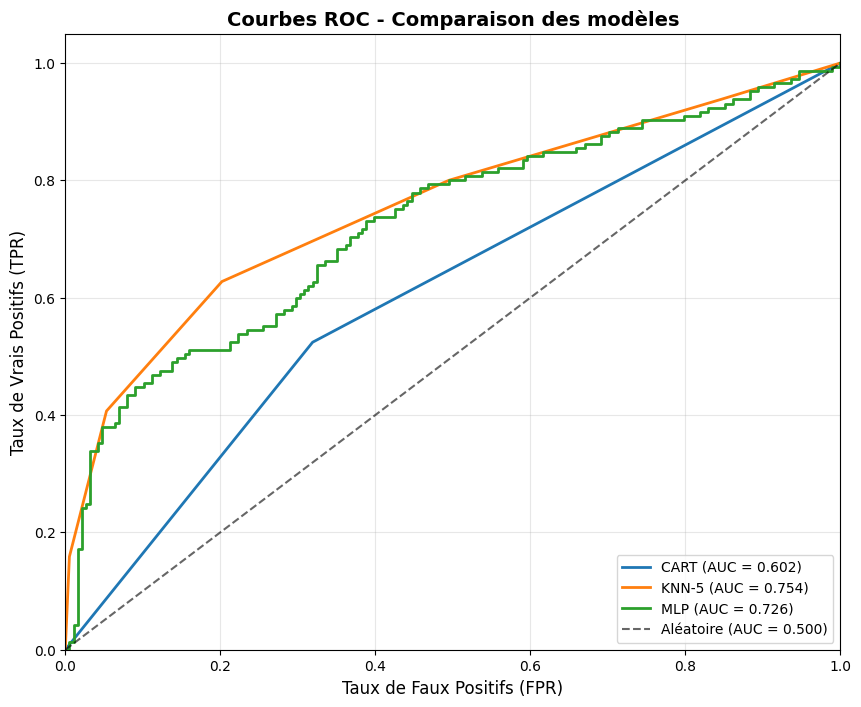


Matrices de confusion :


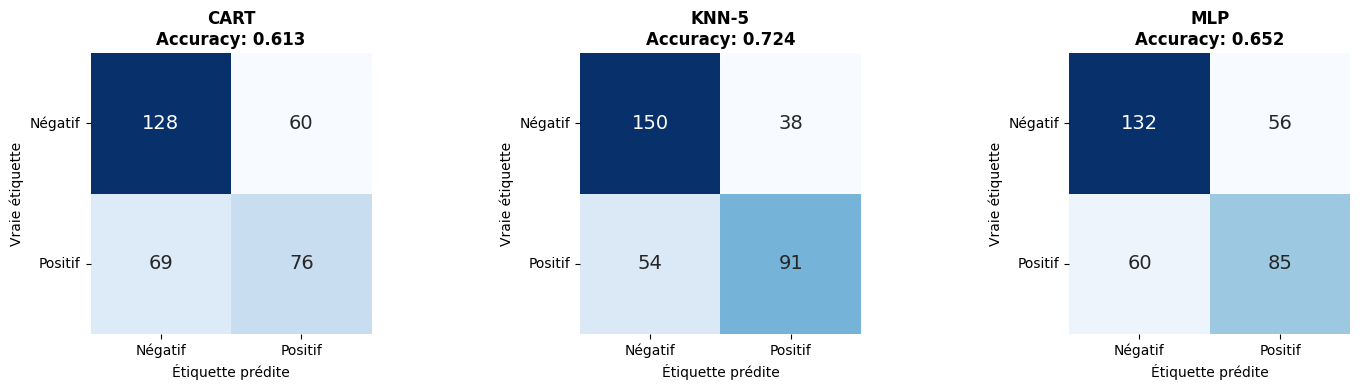


🏆 MEILLEUR MODÈLE SÉLECTIONNÉ: KNN-5


In [306]:
algorithms = {
    'CART': DecisionTreeClassifier(random_state=1),
    'KNN-5': KNeighborsClassifier(n_neighbors=5),
    'MLP': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=1000)
}

# La fonction retourne probablement (best_model, best_name, results)
best_model, best_model_name, all_results_dict = notebook.run_classifiers_train_test(
    X_train, X_test, Y_train, Y_test  # Utilisez Y_train et Y_test (avec majuscule)
)

# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC
print("\nCourbes ROC :")
notebook.plot_roc_curves(all_results_dict)

# Matrices de confusion
print("\nMatrices de confusion :")
notebook.plot_confusion_matrices(all_results_dict)

print(f"\n🏆 MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")

In [307]:
print("Type de all_results:", type(all_results))
print("Contenu de all_results:")
print(all_results)

Type de all_results: <class 'dict'>
Contenu de all_results:
{'CART': {'model': DecisionTreeClassifier(random_state=1), 'metrics': {'accuracy': 0.675, 'precision': 0.631578947368421, 'recall': 0.6666666666666666, 'best_metric': 0.6666666666666666, 'final_score': 0.6708333333333334, 'confusion_matrix': array([[75, 35],
       [30, 60]], dtype=int64), 'fpr': array([0.        , 0.31818182, 1.        ]), 'tpr': array([0.        , 0.66666667, 1.        ]), 'roc_auc': 0.6742424242424243, 'y_pred': array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0,